# Canadian Household Energy Consumption Analysis

## Project Overview

This project analyzes Canadian household energy consumption across provinces
using Statistics Canada data covering 2011, 2013, 2015, 2019, and 2021.

The analysis uses PostgreSQL for data storage, validation, transformation,
and querying, with Python/Jupyter used for visualization and analytical
documentation.

**Data scope:** The latest reference year available in the Statistics Canada household-energy tables used for this analysis is 2021. The selected tables were released with these observations in 2024, so the 2021 endpoint reflects source-data availability. This portfolio project was developed primarily to demonstrate an end-to-end SQL and data-analysis workflow using official data; the findings describe the available historical observations rather than current real-time household energy use. The workflow is structured so that the analysis can be refreshed when newer comparable observations become available.

## Database Connection

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from sqlalchemy import create_engine, URL

In [2]:
load_dotenv("../.env")

db_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("PGUSER"),
    password=os.getenv("PGPASSWORD"),
    host=os.getenv("PGHOST"),
    port=int(os.getenv("PGPORT")),
    database=os.getenv("PGDATABASE")
)

engine = create_engine(db_url)

In [3]:
query = """
SELECT COUNT(*) AS total_rows
FROM clean.overall;
"""

pd.read_sql(query, engine)

,total_rows
0,825


## 1. Historical Provincial Trends

### Analytical Question

How has total household energy consumption per household changed across Canadian provinces from 2011 to 2021?

The analysis uses gigajoules per household (GJ/household) to allow more meaningful comparisons across provinces with different numbers of households.

Available observations occur in 2011, 2013, 2015, 2019, and 2021. Because these years are not evenly spaced, changes between observations should be interpreted as changes across observed intervals rather than continuous annual trends.

In [4]:
trend_query = """
SELECT
    year,
    geography,
    value AS gj_per_household
FROM clean.overall
WHERE energy_type = 'Total, all energy types'
  AND measure = 'Gigajoules per household'
  AND geography <> 'Canada'
ORDER BY geography, year;
"""

trend_df = pd.read_sql(trend_query, engine)

trend_df

,year,geography,gj_per_household
0,2011,Alberta,119.2
1,2013,Alberta,137.1
2,2015,Alberta,117.7
3,2019,Alberta,124.6
4,2021,Alberta,121.8
5,2011,British Columbia,93.2
6,2013,British Columbia,92.1
7,2015,British Columbia,80.3
8,2019,British Columbia,86.7
9,2021,British Columbia,81.2


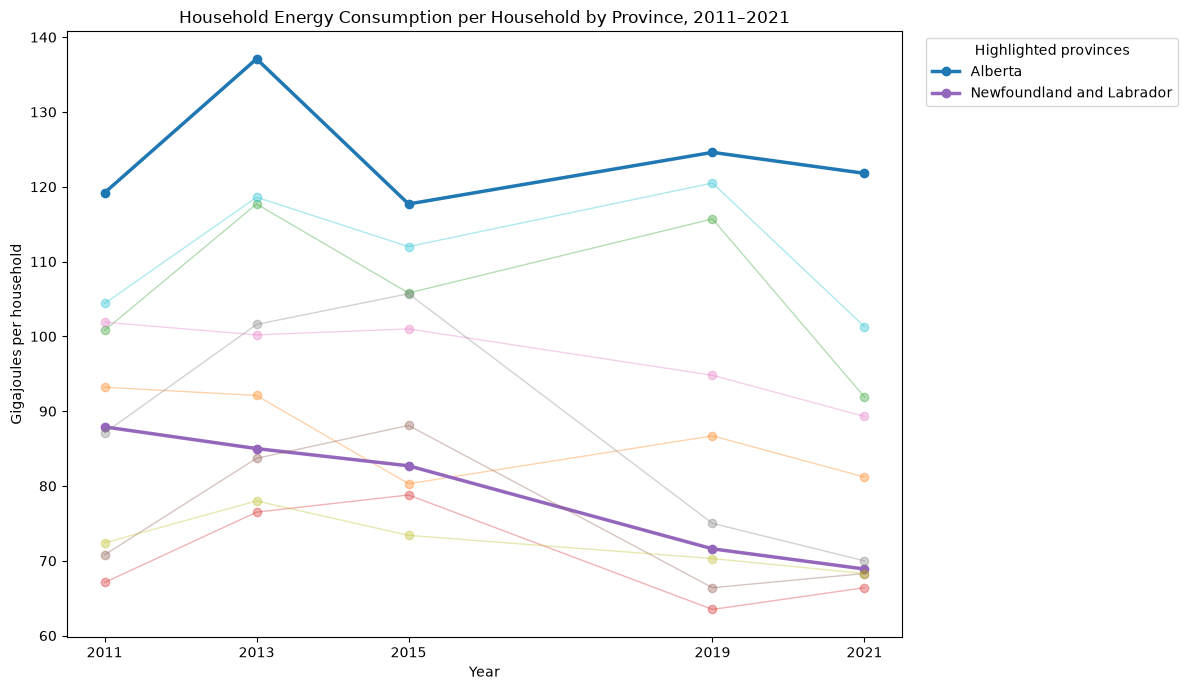

In [5]:
fig, ax = plt.subplots(figsize=(12, 7))

highlighted = ["Alberta", "Newfoundland and Labrador"]

for province, group in trend_df.groupby("geography"):

    if province in highlighted:
        ax.plot(
            group["year"],
            group["gj_per_household"],
            marker="o",
            linewidth=2.5,
            label=province
        )
    else:
        ax.plot(
            group["year"],
            group["gj_per_household"],
            marker="o",
            linewidth=1,
            alpha=0.35
        )

ax.set_title(
    "Household Energy Consumption per Household by Province, 2011–2021"
)

ax.set_xlabel("Year")
ax.set_ylabel("Gigajoules per household")
ax.set_xticks([2011, 2013, 2015, 2019, 2021])

ax.legend(
    title="Highlighted provinces",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

fig.savefig(
    "../outputs/figures/01_historical_provincial_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings
Nine of the ten provinces recorded lower household energy consumption per household in 2021 than in 2011, with Alberta the only province to finish above its starting level. However, provincial trajectories differed substantially across the observed intervals. Newfoundland and Labrador declined in all four intervals, while New Brunswick and Nova Scotia increased in three of four intervals but still ended below their 2011 levels because their single declines were comparatively large.

## 2. 2021 Provincial Comparison

### Analytical Question

How did household energy consumption per household differ across Canadian provinces in 2021, and how did each province compare with the national benchmark?

The analysis compares total household energy consumption per household across the ten provinces using gigajoules per household (GJ/household). Canada's national value is retained separately as a benchmark rather than ranked alongside the provinces.

In [6]:
comparison_query = """
WITH canada_benchmark AS (
    SELECT
        value AS canada_value
    FROM clean.overall
    WHERE year = 2021
      AND energy_type = 'Total, all energy types'
      AND measure = 'Gigajoules per household'
      AND geography = 'Canada'
)

SELECT
    o.geography,
    o.value AS province_value,
    c.canada_value,
    o.value - c.canada_value AS difference_from_canada,
    ROUND(
        (o.value - c.canada_value)
        / c.canada_value * 100,
        2
    ) AS percent_difference_from_canada
FROM clean.overall AS o
CROSS JOIN canada_benchmark AS c
WHERE o.year = 2021
  AND o.energy_type = 'Total, all energy types'
  AND o.measure = 'Gigajoules per household'
  AND o.geography <> 'Canada'
ORDER BY o.value DESC;
"""

comparison_df = pd.read_sql(comparison_query, engine)

comparison_df

,geography,province_value,canada_value,difference_from_canada,percent_difference_from_canada
0,Alberta,121.8,85.4,36.4,42.62
1,Saskatchewan,101.3,85.4,15.9,18.62
2,Manitoba,91.9,85.4,6.5,7.61
3,Ontario,89.3,85.4,3.9,4.57
4,British Columbia,81.2,85.4,-4.2,-4.92
5,Prince Edward Island,70.0,85.4,-15.4,-18.03
6,Newfoundland and Labrador,68.9,85.4,-16.5,-19.32
7,Quebec,68.3,85.4,-17.1,-20.02
8,Nova Scotia,68.3,85.4,-17.1,-20.02
9,New Brunswick,66.4,85.4,-19.0,-22.25


In [7]:
chart_df = comparison_df.sort_values(
    "province_value",
    ascending=True
)

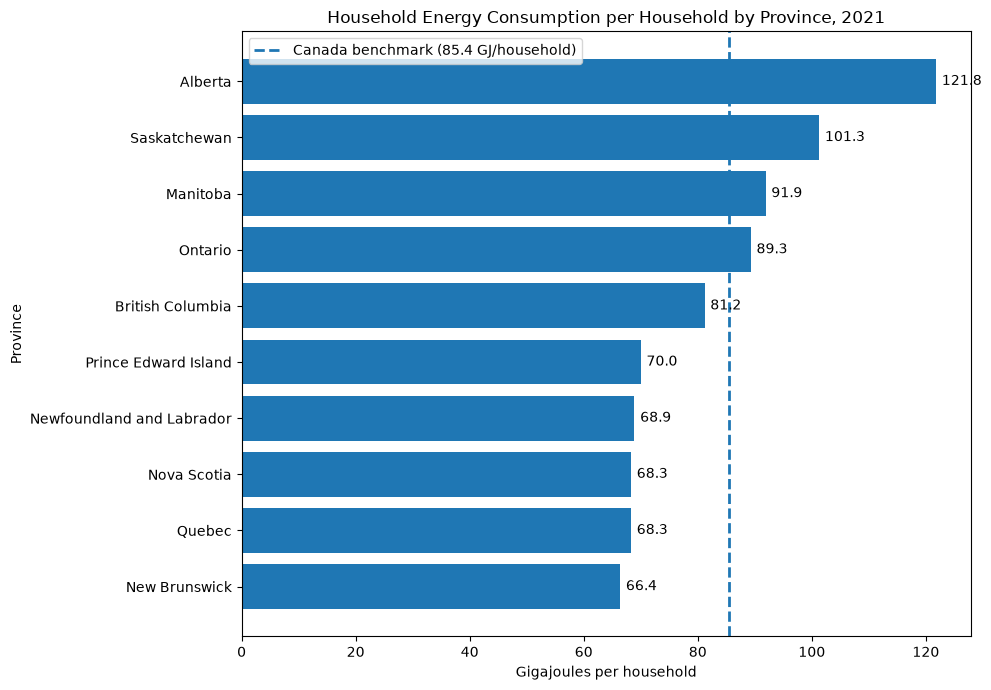

In [8]:
canada_value = comparison_df["canada_value"].iloc[0]

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    chart_df["geography"],
    chart_df["province_value"]
)

ax.axvline(
    x=canada_value,
    linestyle="--",
    linewidth=2,
    label=f"Canada benchmark ({canada_value:.1f} GJ/household)"
)

ax.set_title(
    "Household Energy Consumption per Household by Province, 2021"
)

ax.set_xlabel("Gigajoules per household")
ax.set_ylabel("Province")

ax.legend()

for index, row in chart_df.reset_index(drop=True).iterrows():
    ax.text(
        row["province_value"] + 1,
        index,
        f'{row["province_value"]:.1f}',
        va="center"
    )

plt.tight_layout()

fig.savefig(
    "../outputs/figures/02_2021_provincial_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings
Across the ten provinces, household energy consumption per household spanned 55.4 GJ/household in 2021, ranging from 121.8 GJ/household in Alberta to 66.4 GJ/household in New Brunswick. Compared with the national benchmark of 85.4 GJ/household, four provinces—Alberta, Saskatchewan, Manitoba, and Ontario—recorded higher consumption, while the remaining six were below it. Alberta stood furthest above the national benchmark at 42.62%, while New Brunswick was furthest below it at 22.25%, indicating substantial geographic variation in household energy intensity across Canada.

## 3. Provincial Energy-Source Patterns

### Analytical Question

How did household energy-source patterns differ across Canadian provinces in 2021?

Two complementary measures are used:

- **Gigajoules per household** to compare consumption intensity for each fuel across provinces with published observations.
- **Proportion of total energy** to examine the role each fuel plays in a province's overall household energy mix.

Electricity has complete provincial coverage, while some natural-gas and heating-oil observations are suppressed. Suppressed (`F`) observations are treated as unavailable rather than zero, while published estimates marked `E` are retained with caution.

In [9]:
intensity_query = """
WITH ranked_fuels AS (
    SELECT
        geography,
        energy_type,
        value,
        status,

        RANK() OVER (
            PARTITION BY energy_type
            ORDER BY value DESC
        ) AS rank_high_to_low,

        RANK() OVER (
            PARTITION BY energy_type
            ORDER BY value ASC
        ) AS rank_low_to_high

    FROM clean.overall

    WHERE year = 2021
      AND energy_type IN (
          'Electricity',
          'Natural gas',
          'Heating oil'
      )
      AND measure = 'Gigajoules per household'
      AND geography <> 'Canada'
      AND value IS NOT NULL
)

SELECT
    geography,
    energy_type,
    value AS gj_per_household,
    status,
    rank_high_to_low,
    rank_low_to_high
FROM ranked_fuels
WHERE rank_high_to_low = 1
   OR rank_low_to_high = 1
ORDER BY
    energy_type,
    value DESC;
"""

intensity_extremes_df = pd.read_sql(intensity_query, engine)

intensity_extremes_df

,geography,energy_type,gj_per_household,status,rank_high_to_low,rank_low_to_high
0,Quebec,Electricity,61.6,NaN,1,10
1,Alberta,Electricity,23.3,NaN,10,1
2,Newfoundland and Labrador,Heating oil,64.7,NaN,1,6
3,Prince Edward Island,Heating oil,57.9,NaN,6,1
4,Alberta,Natural gas,109.3,NaN,1,7
5,New Brunswick,Natural gas,55.4,E,7,1


### Fuel Consumption Intensity

Consumption intensity varied considerably across provinces for individual fuels. Among published observations, Quebec recorded the highest electricity consumption per household, Newfoundland and Labrador the highest heating-oil consumption, and Alberta the highest natural-gas consumption. Natural-gas intensity showed particularly large geographic variation, although New Brunswick's low-end estimate carries an `E` quality flag and should be interpreted cautiously.

In [10]:
fuel_mix_query = """
WITH fuel_mix AS (
    SELECT
        geography,

        MAX(value) FILTER (
            WHERE energy_type = 'Electricity'
        ) AS electricity_pct,

        MAX(value) FILTER (
            WHERE energy_type = 'Natural gas'
        ) AS natural_gas_pct,

        MAX(value) FILTER (
            WHERE energy_type = 'Heating oil'
        ) AS heating_oil_pct,

        COUNT(*) FILTER (
            WHERE status = 'F'
        ) AS suppressed_fuels

    FROM clean.overall

    WHERE year = 2021
      AND measure = 'Proportion of total energy'
      AND energy_type IN (
          'Electricity',
          'Natural gas',
          'Heating oil'
      )
      AND geography <> 'Canada'

    GROUP BY geography
)

SELECT
    geography,
    electricity_pct,
    natural_gas_pct,
    heating_oil_pct,
    suppressed_fuels,

    CASE
        WHEN electricity_pct > 50 THEN 'Electricity'
        WHEN natural_gas_pct > 50 THEN 'Natural gas'
        WHEN heating_oil_pct > 50 THEN 'Heating oil'
        ELSE 'No clear majority'
    END AS dominant_fuel,

    CASE
        WHEN electricity_pct > 50 THEN electricity_pct
        WHEN natural_gas_pct > 50 THEN natural_gas_pct
        WHEN heating_oil_pct > 50 THEN heating_oil_pct
        ELSE NULL
    END AS dominant_share

FROM fuel_mix

ORDER BY geography;
"""

fuel_mix_df = pd.read_sql(fuel_mix_query, engine)

fuel_mix_df

,geography,electricity_pct,natural_gas_pct,heating_oil_pct,suppressed_fuels,dominant_fuel,dominant_share
0,Alberta,19.1,80.9,NaN,1,Natural gas,80.9
1,British Columbia,40.0,59.7,NaN,1,Natural gas,59.7
2,Manitoba,46.3,53.7,NaN,1,Natural gas,53.7
3,New Brunswick,87.6,NaN,7.7,1,Electricity,87.6
4,Newfoundland and Labrador,79.3,NaN,20.7,1,Electricity,79.3
5,Nova Scotia,56.0,NaN,38.3,1,Electricity,56.0
6,Ontario,33.6,65.3,1.2,0,Natural gas,65.3
7,Prince Edward Island,49.7,NaN,50.3,1,Heating oil,50.3
8,Quebec,90.3,5.7,4.1,0,Electricity,90.3
9,Saskatchewan,24.9,75.1,NaN,1,Natural gas,75.1


In [11]:
fuel_mix_df["dominant_fuel"].value_counts()

dominant_fuel
Natural gas    5
Electricity    4
Heating oil    1
Name: count, dtype: int64

In [12]:
fuel_mix_chart_df = fuel_mix_df.sort_values(
    "dominant_share",
    ascending=True
)

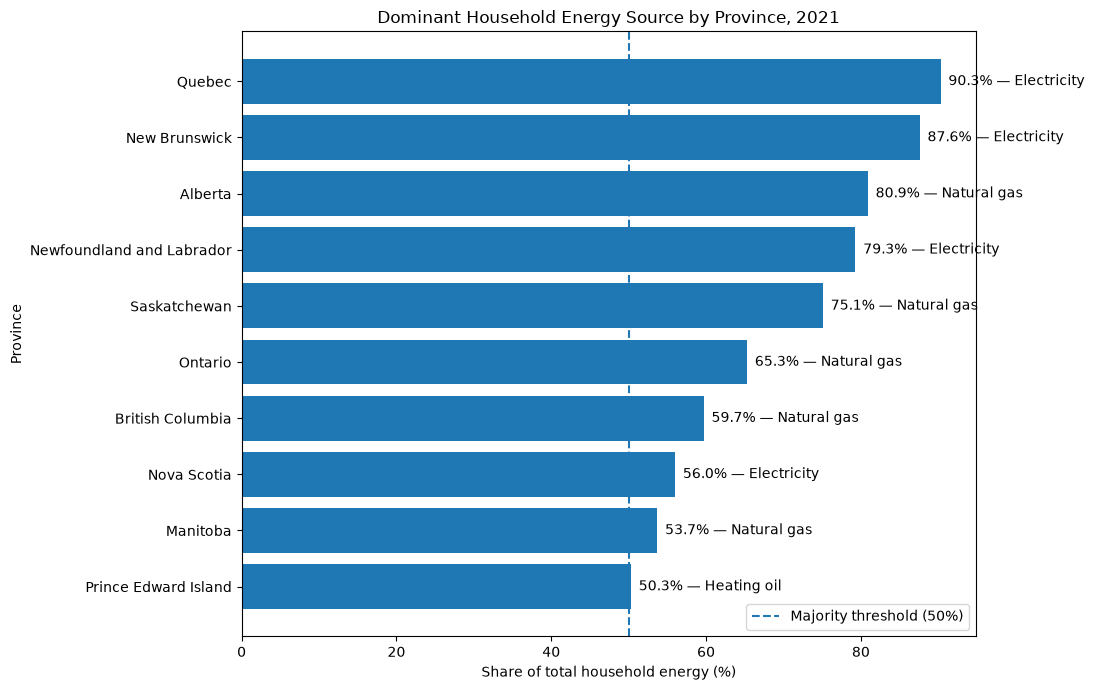

In [13]:
fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    fuel_mix_chart_df["geography"],
    fuel_mix_chart_df["dominant_share"]
)

ax.axvline(
    50,
    linestyle="--",
    linewidth=1.5,
    label="Majority threshold (50%)"
)

ax.set_title(
    "Dominant Household Energy Source by Province, 2021"
)

ax.set_xlabel("Share of total household energy (%)")
ax.set_ylabel("Province")

for bar, (_, row) in zip(
    bars,
    fuel_mix_chart_df.iterrows()
):
    ax.text(
        row["dominant_share"] + 1,
        bar.get_y() + bar.get_height() / 2,
        f'{row["dominant_share"]:.1f}% — {row["dominant_fuel"]}',
        va="center"
    )

ax.legend()

plt.tight_layout()

fig.savefig(
    "../outputs/figures/03_dominant_energy_source_by_province.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Key Findings

Household energy-source patterns varied substantially across Canadian provinces in 2021. Among households using each respective fuel, Quebec recorded the highest published electricity consumption intensity, Newfoundland and Labrador the highest heating-oil intensity, and Alberta the highest natural-gas intensity. Fuel-mix analysis showed that natural gas was the dominant household energy source in five provinces, electricity in four, and heating oil only in Prince Edward Island, where it narrowly exceeded electricity at 50.3%.

Some natural-gas and heating-oil observations were suppressed, limiting direct comparisons across all ten provinces. However, the dominant-fuel classifications remain supported because the identified leading fuel accounted for more than 50% of total household energy consumption in every province, meaning a suppressed category could not overturn the majority classification. New Brunswick's natural-gas consumption-intensity estimate should also be interpreted cautiously because it carries an E quality flag.

## 4. Dwelling-Type Energy Consumption

### Analytical Question

How did household energy consumption per household differ across dwelling types in Canada in 2021?

The analysis compares total household energy consumption across seven dwelling types using gigajoules per household (GJ/household). The selected 2021 Canada-level slice contains complete published values for all dwelling categories with no `F` or `E` quality flags.

In [14]:
dwelling_query = """
SELECT
    dwelling_type,
    value AS gj_per_household
FROM clean.dwelling
WHERE year = 2021
  AND geography = 'Canada'
  AND energy_type = 'Total, all energy types'
  AND measure = 'Gigajoules per household'
ORDER BY value DESC;
"""

dwelling_df = pd.read_sql(dwelling_query, engine)

dwelling_df

,dwelling_type,gj_per_household
0,Single-detached,108.7
1,Double,92.3
2,Row or terrace,80.8
3,Duplex,77.7
4,Mobile home,67.9
5,Low-rise apartment (fewer than 5 stories),44.3
6,High-rise apartment (5 stories or more),43.2


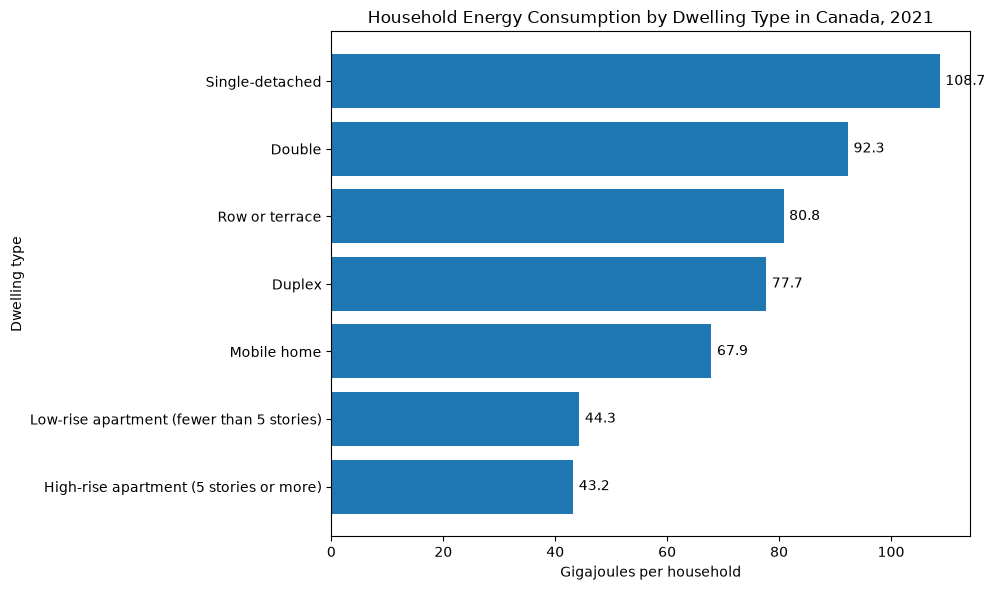

In [15]:
# Sort so the largest value appears at the top of the horizontal chart
dwelling_chart_df = dwelling_df.sort_values(
    "gj_per_household",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    dwelling_chart_df["dwelling_type"],
    dwelling_chart_df["gj_per_household"]
)

ax.set_title(
    "Household Energy Consumption by Dwelling Type in Canada, 2021"
)

ax.set_xlabel("Gigajoules per household")
ax.set_ylabel("Dwelling type")

# Add the exact value beside each bar
for bar, value in zip(
    bars,
    dwelling_chart_df["gj_per_household"]
):
    ax.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}",
        va="center"
    )

plt.tight_layout()

fig.savefig(
    "../outputs/figures/04_dwelling_type_energy_consumption.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings

Household energy consumption per household varied substantially across dwelling types in Canada in 2021. Single-detached homes recorded the highest consumption at 108.7 GJ/household, while high-rise apartments recorded the lowest at 43.2 GJ/household, a difference of 65.5 GJ/household. Single-detached households therefore consumed approximately 151.6% more energy per household than high-rise apartment households, or about 2.5 times as much. More broadly, apartment dwellings occupied the lower end of the consumption range, while single-detached and double dwellings recorded the highest levels. The dataset establishes this association but does not identify the underlying causes of the differences.

## 5. Household Income and Energy Consumption

### Analytical Question

How did household energy consumption per household differ across household-income groups in Canada in 2021?

The analysis compares total household energy consumption across seven published income brackets using gigajoules per household (GJ/household). The selected 2021 Canada-level observations contain complete published values with no `F` or `E` quality flags.

In [16]:
income_query = """
SELECT
    household_income,
    value AS gj_per_household
FROM clean.income
WHERE year = 2021
  AND geography = 'Canada'
  AND energy_type = 'Total, all energy types'
  AND measure = 'Gigajoules per household'
ORDER BY
    CASE household_income
        WHEN 'Under $20,000 (includes income loss)' THEN 1
        WHEN '$20,000 to $39,999' THEN 2
        WHEN '$40,000 to $59,999' THEN 3
        WHEN '$60,000 to $79,999' THEN 4
        WHEN '$80,000 to $99,999' THEN 5
        WHEN '$100,000 to $149,999' THEN 6
        WHEN '$150,000 and more' THEN 7
    END;
"""

income_df = pd.read_sql(income_query, engine)

income_df

,household_income,gj_per_household
0,"Under $20,000 (includes income loss)",55.8
1,"$20,000 to $39,999",64.9
2,"$40,000 to $59,999",74.9
3,"$60,000 to $79,999",82.0
4,"$80,000 to $99,999",84.3
5,"$100,000 to $149,999",94.8
6,"$150,000 and more",114.4


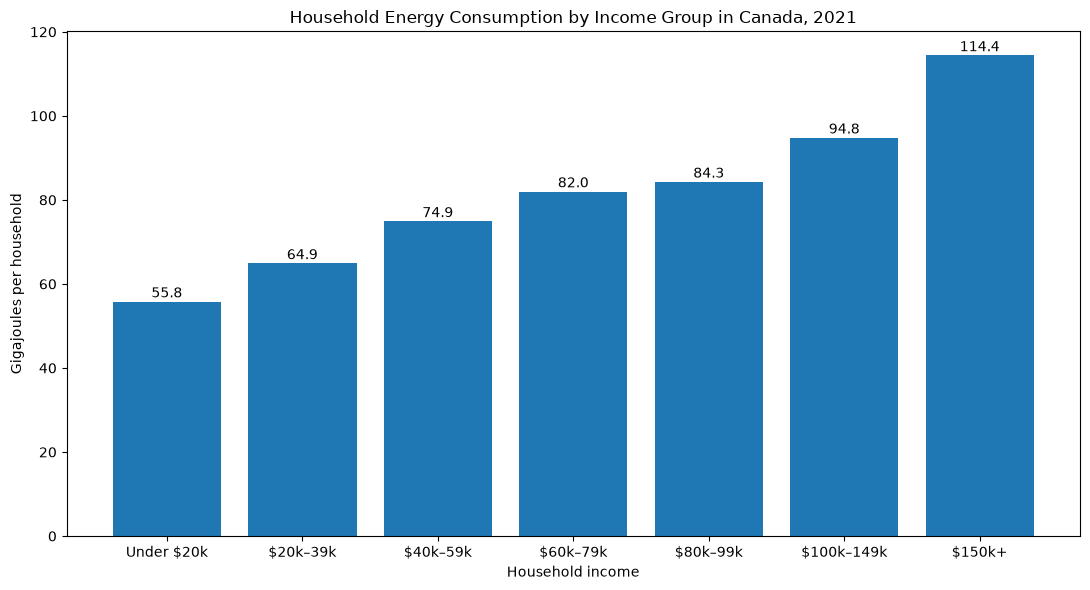

In [18]:
# Create shorter labels for the chart only
income_chart_df = income_df.copy()


income_chart_df["income_label"] = [
    "Under $20k",
    "$20k–39k",
    "$40k–59k",
    "$60k–79k",
    "$80k–99k",
    "$100k–149k",
    "$150k+"
]
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    income_chart_df["income_label"],
    income_chart_df["gj_per_household"]
)

ax.set_title(
    "Household Energy Consumption by Income Group in Canada, 2021"
)

ax.set_xlabel("Household income")
ax.set_ylabel("Gigajoules per household")

# Add exact values above each bar
for bar, value in zip(
    bars,
    income_chart_df["gj_per_household"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.1f}",
        ha="center"
    )

plt.tight_layout()

fig.savefig(
    "../outputs/figures/05_income_energy_consumption.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings

Household energy consumption per household increased consistently across successive income groups in Canada in 2021. Consumption rose from 55.8 GJ/household for households earning under CAD 20,000 to 114.4 GJ/household for households earning CAD 150,000 or more. This represents a difference of 58.6 GJ/household, with the highest-income group consuming approximately 105.0% more energy per household—or about 2.05 times as much—as the lowest-income group.

The pattern shows a clear positive association between household income and energy consumption in the 2021 data. However, the analysis does not establish that higher income itself causes higher consumption, since other factors such as dwelling characteristics, household size, heating systems, and other behavioural or structural differences are not controlled for.

## 6. Overall Conclusions

This analysis documents substantial variation in Canadian household energy consumption across provinces, energy sources, dwelling types, and household-income groups.

Across the available observations from 2011 to 2021, nine of the ten provinces recorded lower household energy consumption per household in 2021 than in 2011. Alberta was the only province to finish above its 2011 level. These endpoint differences should not be interpreted as continuous annual trends, since observations are available only for 2011, 2013, 2015, 2019, and 2021.

In 2021, provincial household energy consumption ranged from 121.8 GJ/household in Alberta to 66.4 GJ/household in New Brunswick, producing a provincial spread of 55.4 GJ/household. Four provinces recorded consumption above the national Statistics Canada benchmark of 85.4 GJ/household, while six were below it.

Household energy-source patterns also differed across provinces. Natural gas represented more than half of total household energy consumption in five provinces, electricity did so in four, and heating oil narrowly exceeded 50% in Prince Edward Island. Comparisons of individual fuel-consumption intensity were limited to published observations because some natural-gas and heating-oil values were suppressed.

The Canada-level 2021 data also showed substantial differences across dwelling types. Single-detached homes recorded 108.7 GJ/household compared with 43.2 GJ/household for high-rise apartments, meaning the single-detached value was approximately 2.5 times as large.

Household energy consumption also increased across each successive published income bracket in the 2021 Canada-level data, from 55.8 GJ/household for households earning under CAD 20,000 to 114.4 GJ/household for households earning CAD 150,000 or more. The highest-income category therefore recorded approximately 2.05 times the consumption per household of the lowest-income category.

Taken together, these results show that household energy consumption differs substantially depending on the dimension being examined. However, the provincial, fuel, dwelling-type, and income analyses were conducted separately. The results therefore describe observed patterns and associations within the Statistics Canada data; they do not establish causal relationships or determine the combined effect of these factors on household energy consumption.

## 7. Data Limitations

Several limitations should be considered when interpreting the results of this analysis.

First, the historical dataset contains observations for only 2011, 2013, 2015, 2019, and 2021. Because these years are unevenly spaced, changes between observations represent differences across the available intervals rather than continuous annual trends. The analysis therefore does not infer what occurred during the unobserved years.

Second, data availability varies by energy source. Electricity observations were complete for the provincial comparisons used in this project, while several natural-gas and heating-oil observations were suppressed and marked `F`. These suppressed observations were treated as unavailable rather than as zero values. Published estimates marked `E` were retained but interpreted cautiously because Statistics Canada identifies them as estimates requiring additional caution.

The total household energy measure used in this project covers electricity, natural gas, and heating oil; other household energy sources such as propane, wood, coal, and other sources are outside the scope of the selected Statistics Canada tables.

Coverage also differs across the supplementary dwelling-type and household-income datasets. Not every statistical series contains observations for all five study years. For example, the household-income category “Income not stated” appears in the earlier years but is absent from 2019 and 2021. Validation rules were therefore based on the structure of each dataset rather than assuming that every series should contain five observations.

The dwelling-type and household-income analyses use Canada-level 2021 observations and describe differences between categories at a single point in time. These comparisons do not control for other characteristics that may also be related to household energy consumption, such as household size, dwelling size, building age, climate, heating technology, or occupancy patterns.

Finally, the analyses of geography, fuel type, dwelling type, and household income were conducted separately. The project therefore identifies descriptive patterns and associations but does not estimate causal effects or determine how these factors jointly influence household energy consumption.

These limitations do not invalidate the observed comparisons, but they define the scope within which the findings should be interpreted.

